# Lab01 - sprint 2

В спринте 1 мы показали, что величина **X1** (интенсивность рамановского сигнала на 500.33 см⁻¹) хорошо описывается нормальным распределением: асимметрия 0.048, эксцесс -0.353, критерий Шапиро-Уилка не отверг нормальность (p = 0.071).

Поэтому в спринте 2 мы строим **два датчика нормальных случайных чисел** и настраиваем их на X1. Каждый датчик сделан по своей статье-первоисточнику:

| № | Метод | Первоисточник |
|---|-------|---------------|
| 1 | Полярный метод (метод полярных координат) | Marsaglia G., Bray T. A. *A Convenient Method for Generating Normal Variables* // SIAM Review. 1964. Vol. 6, № 3. P. 260–264. doi:10.1137/1006063 |
| 2 | Метод отношений равномерных величин (ratio-of-uniforms) | Kinderman A. J., Monahan J. F. *Computer Generation of Random Variables Using the Ratio of Uniform Deviates* // ACM Transactions on Mathematical Software. 1977. Vol. 3, № 3. P. 257–260. doi:10.1145/355744.355750 |

Общая схема работы обоих датчиков:

```
вихрь Мерсенна  →  U(0,1)  →  [метод из статьи]  →  Z ~ N(0,1)  →  X = μ + σ·Z  ≈  X1
```

Что мы проверяем для каждого датчика:
1. Код из статьи реализован правильно.
2. Датчик действительно выдаёт N(0,1) - сравнение с теорией на большой выборке.
3. Сгенерированные значения похожи на реальные X1 - сравнение метрик и критерии согласия.

## Подготовка: данные X1 и приведение к стандартному нормальному

In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Загружаем данные так же, как в спринте 1
base_url = "https://raw.githubusercontent.com/Alvaro-FG/Raman_Sugars/main/"
spectra = pd.read_csv(base_url + "Sugar_Concentration_Test_ALL_spectra.csv")

# Ищем ближайшую к 500 см⁻¹ точку спектра
wavenumbers = spectra["Wavenumber [cm-1]"].to_numpy()
idx_500 = np.abs(wavenumbers - 500).argmin()

# Строка спектра = одна частота, столбцы = измерения. Берём строку и превращаем в вектор
X1 = spectra.iloc[idx_500, 1:].astype(float).to_numpy()

mu_hat = X1.mean()           # оценка мат. ожидания
sigma_hat = X1.std(ddof=1)   # несмещённая оценка стандартного отклонения
N_REAL = len(X1)

print(f"Частота: {wavenumbers[idx_500]:.2f} см⁻¹")
print(f"Число измерений: {N_REAL}")
print(f"Оценка μ (среднее) = {mu_hat:.3f}")
print(f"Оценка σ (стандартное отклонение) = {sigma_hat:.3f}")

Частота: 500.33 см⁻¹
Число измерений: 1960
Оценка μ (среднее) = 3550.865
Оценка σ (стандартное отклонение) = 428.902


**Зачем нам стандартное нормальное распределение?**

Оба метода из статей генерируют числа из **стандартного** нормального распределения N(0, 1). Это не ограничение, а удобство: у нормального распределения есть свойство линейности -

$$Z \sim N(0,1) \;\Rightarrow\; X = \mu + \sigma Z \sim N(\mu, \sigma^2).$$

По этому свойству, мы можем превратить сгенерированные Z в числа (выразить Z из формулы), похожие на наши данные, еоторые будут иметь ту же самую дисперсию и среднее значение. Тогда достаточно один раз написать хороший генератор N(0,1), а затем подставить оценки $\hat\mu$, $\hat\sigma$, полученные по X1. Обратное преобразование $Z = (X - \hat\mu)/\hat\sigma$ — это та же стандартизация, которую мы делали в спринте 1 через `StandardScaler`.

### Источник равномерных чисел: вихрь Мерсенна

Оба метода - это **преобразования** равномерных случайных чисел U(0,1) в нормальные. Значит, нужен базовый датчик равномерных чисел. Мы берём вихрь Мерсенна MT19937 (Matsumoto, Nishimura, 1998). Его период $2^{19937}-1$, Даже если генерировать миллиард чисел в секунду с момента Большого взрыва, до повтора не дойти). Число вида 2ⁿ-1, если оно простое, называют простым числом Мерсенна, в честь французского монаха и математика XVII века Марена Мерсенна.

Мы оборачиваем MT19937 в маленький класс, который **считает, сколько равномерных чисел потрачено**, то есть берём 2 равномерных числа и получаем точку в квадрате (от -1 до 1 по обеим осям), потом вычисляем, если эта точка попадает в круг (от -1 до 1 по обеим осям), если точка внутри круга, из неё получается 2 нормальных числа;
если снаружи, числа выброшены впустую, пробуем снова. Это нужно, чтобы потом сравнить экономичность двух методов с теоретическими значениями (узнать долю выброшенных точек).

In [10]:
class UniformSource:

    def __init__(self, seed):
        self.rng = np.random.Generator(np.random.MT19937(seed)) # создаем вихрь с заданным зерном
        self.used = 0  # сколько равномерных чисел уже выдали

    def one(self):
        self.used += 1 # Одно число U[0,1)
        return self.rng.random()

    def many(self, shape):
        arr = self.rng.random(shape) # Массив чисел U[0,1)
        self.used += arr.size
        return arr

# Быстрая проверка: равномерные числа действительно равномерные
u_check = UniformSource(seed=1).many(100_000)
print("Среднее (теория 0.5):    ", round(u_check.mean(), 4))
print("Дисперсия (теория 1/12 ≈ 0.0833):", round(u_check.var(), 4))
print("Тест Колмогорова против U(0,1): p =", round(stats.kstest(u_check, "uniform").pvalue, 3))

Среднее (теория 0.5):     0.4998
Дисперсия (теория 1/12 ≈ 0.0833): 0.0834
Тест Колмогорова против U(0,1): p = 0.96


### Общие функции для проверок

Чтобы сравнивать реальные данные и датчики одинаково, заведём одну функцию с метриками. Набор метрик тот же, что в спринте 1: среднее, стандартное отклонение, асимметрия, эксцесс, квантили. Конкретно что будем сравнивать: 
1. Cгенерированные Z с идеальным N(0, 1), то есть с теорией, без реальных данных. Это ответ на вопрос правильно ли работает метод из статьи.
2. Сравнение сгенерированных значений с реальными X1.
3. Гистограммы и Q-Q график: реальные X1 против сгенерированных.
4. Q-Q: квантили реальных против квантилей сгенерированных. Если распределения совпадают, точки лежат на диагонали.

In [17]:
def metrics(sample):
    """Набор описательных статистик выборки."""
    sample = np.asarray(sample)
    return {
        "n": len(sample),
        "mean": sample.mean(),
        "std": sample.std(ddof=1),
        "skew": stats.skew(sample),
        "kurt (excess)": stats.kurtosis(sample),   # у нормального = 0
        "q05": np.quantile(sample, 0.05),
        "q25": np.quantile(sample, 0.25),
        "median": np.median(sample),
        "q75": np.quantile(sample, 0.75),
        "q95": np.quantile(sample, 0.95),
    }


def check_standard_normal(z, name):
    """ Сравнивает сгенерированные Z с идеальным N(0, 1), то есть с теорией, без реальных данных. 
    Это ответ на вопрос правильно ли работает метод из статьи"""
    m = metrics(z)
    ks = stats.kstest(z, "norm")                 # критерий Колмогорова
    sw = stats.shapiro(z[:5000])                 # Шапиро–Уилк (на первых 5000)
    theory = {"mean": 0, "std": 1, "skew": 0, "kurt (excess)": 0,
              "q05": stats.norm.ppf(0.05), "q25": stats.norm.ppf(0.25),
              "median": 0, "q75": stats.norm.ppf(0.75), "q95": stats.norm.ppf(0.95)}
    table = pd.DataFrame({"датчик": {k: m[k] for k in theory}, "теория N(0,1)": theory})
    table["разница"] = table["датчик"] - table["теория N(0,1)"]
    print(f" {name}: сравнение с N(0,1)")
    print(table.round(4))
    print(f"\nКолмогоров:   D = {ks.statistic:.4f}, p = {ks.pvalue:.3f}")
    print(f"Шапиро–Уилк:  W = {sw.statistic:.4f}, p = {sw.pvalue:.3f}")
    return ks.pvalue, sw.pvalue


def compare_with_real(real, generated, name):
    """Сравнение сгенерированных значений с РЕАЛЬНЫМИ X1."""
    table = pd.DataFrame({"X1 (реальные)": metrics(real), name: metrics(generated)})
    table["разница, %"] = (table[name] - table["X1 (реальные)"]) / table["X1 (реальные)"].abs() * 100
    print(table.round(3))
    ks2 = stats.ks_2samp(real, generated)        # двухвыборочный Колмогоров–Смирнов
    print(f"\nДвухвыборочный Колмогоров–Смирнов: D = {ks2.statistic:.4f}, p = {ks2.pvalue:.3f}")
    return ks2.pvalue


def plot_vs_real(real, generated, name):
    """Гистограммы и Q-Q график: реальные X1 против сгенерированных."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    bins = np.linspace(min(real.min(), generated.min()), max(real.max(), generated.max()), 35)
    axes[0].hist(real, bins=bins, density=True, alpha=0.55, edgecolor="black", label="X1 реальные")
    axes[0].hist(generated, bins=bins, density=True, alpha=0.55, edgecolor="black", label=name)
    axes[0].set_title("Гистограммы плотности")
    axes[0].set_xlabel("Интенсивность")
    axes[0].legend()

    # Q-Q: квантили реальных против квантилей сгенерированных.
    # Если распределения совпадают, точки лежат на диагонали.
    q = np.linspace(0.005, 0.995, 200)
    axes[1].scatter(np.quantile(real, q), np.quantile(generated, q), s=12)
    lim = [bins[0], bins[-1]]
    axes[1].plot(lim, lim, "r--", label="y = x")
    axes[1].set_title("Q-Q: реальные vs сгенерированные")
    axes[1].set_xlabel("Квантили X1")
    axes[1].set_ylabel(f"Квантили: {name}")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## random 01 - Полярный метод Марсальи-Брэя

### Description

**Статья:** Marsaglia G., Bray T. A. *A Convenient Method for Generating Normal Variables* // SIAM Review. 1964. Vol. 6, № 3. P. 260–264. doi:10.1137/1006063.

**Идея.** Исторически раньше появилось преобразование Бокса–Мюллера (1958): из двух равномерных чисел $U_1, U_2$ получают две нормальные

$$Z_1 = \sqrt{-2\ln U_1}\cos(2\pi U_2), \qquad Z_2 = \sqrt{-2\ln U_1}\sin(2\pi U_2).$$

У него есть практический недостаток: на каждую пару нужно вычислить $\cos$ и $\sin$, а это дорогие операции. Марсалья и Брэй предложили получать «случайный угол» без тригонометрии: берём случайную точку в квадрате $[-1,1]^2$ и оставляем её, только если она попала внутрь единичного круга. Тогда $\cos\theta = V_1/\sqrt{S}$ и $\sin\theta = V_2/\sqrt{S}$, где $S = V_1^2+V_2^2$, - синус и косинус получаются из координат точки без затрат памяти!

**Где используется.** 

В компьютерном моделировании для симуляции физических процессов, для создания реалистичного рельефа.

В создании видеоигр для расчета случайного разброса пуль при стрельбе, вероятности критического удара и др.

В статистическом анализе для проведения экспериментов, где нужно симулировать погрешности измерений или естественно менять данные.

В языках программирования, например, метод java.util.Random.nextGaussian() в Java исторически реализован именно на основе полярного метода Марсальи.

**Сильные стороны:** простой, точный, нет $\sin/\cos$, за один удачный шаг выдаёт сразу две независимые нормальные величины.

**Слабые стороны:** некоторое количество точек выбрасываются, из-за непопадания в круг, поэтому число итераций случайно, что мы и учитываем, так как генератор работает на основании вихря Мерсенна.

### MATH DESC

**Алгоритм (как в статье):**
1. Сгенерировать $U_1, U_2 \sim U(0,1)$ и положить $V_1 = 2U_1 - 1$, $V_2 = 2U_2 - 1$ (точка в квадрате $[-1,1]^2$).
2. Вычислить $S = V_1^2 + V_2^2$. Если $S \ge 1$ или $S = 0$ — вернуться к шагу 1.
3. Вернуть $Z_1 = V_1\sqrt{\dfrac{-2\ln S}{S}}, \quad Z_2 = V_2\sqrt{\dfrac{-2\ln S}{S}}.$

**Как это устроено?**

**1. Точка равномерна в круге.**
После отброса координат, которые дают нам лишние точки, то есть те, которые не папали в наш круг, точка $(V_1, V_2)$ равномерно распределена в единичном круге (мы просто отрезали лишнее от равномерного квадрата). Вероятность принятия данной рандомной точки = площадь круга / площадь квадрата $= \pi/4 \approx 0.785$.

**2. $S$ равномерна на (0,1), угол равномерен, и они независимы.**

Пусть $\theta$ - полярный угол точки. Вероятность того, что точка попала в круг радиуса $\sqrt{s}$:
$$P(S \le s) = \frac{\pi (\sqrt{s})^2}{\pi} = s, \quad 0<s<1,$$
Получается, что вероятность S всегда равна самому числу s. Это и означает, что S равномерно распределена от 0 до 1. Вот пример для наглядности: $$P (0{,}2<S<0{,}4)=0{,}4-0{,}2=0{,}2$$
И точно так же: $$P(0{,}6<S<0{,}8)=0{,}8-0{,}6=0{,}2$$
Оба промежутка имеют одинаковую длину 0,2, и вероятность попасть в каждый из них тоже одинаковая. 

**3. Радиус $R = \sqrt{-2\ln S}$ имеет распределение Рэлея.**
$$P(R > r) = P(-2\ln S > r^2) = P(S < e^{-r^2/2}) = e^{-r^2/2}.$$
То есть распределение Рэлея - это новая величина, она описывает, каким должно быть расстояние от центра, чтобы две координаты получились стандартно нормальными, так как нам нужно, что бы согласно нормальному распределению, значения были сосредоточены около нуля в большей степени (колокообразная форма).

**4. Пара независимых N(0,1) в полярных координатах.**

Совместная плотность двух независимых $N(0,1)$:
$$f(z_1, z_2) = \frac{1}{2\pi} e^{-(z_1^2+z_2^2)/2}.$$
Переходим к полярным координатам $z_1 = r\cos\theta$, $z_2 = r\sin\theta$ (что бы перейти к новым координатом, нам нужен якобиан, он всегда равен $r$ в полярных координатах):
$$f(r, \theta) = {\frac{1}{2\pi}} \cdot {r e^{-r^2/2}}.$$
Плотность распалась на произведение (первая часть описывает распределение угла, вторая - распределение расстояния от центра). Значит, равномерный угол и рэлеевский радиус независимы, ч.т.д! Ура! 

**5. Итого.** $\cos\theta = V_1/\sqrt S$, $\sin\theta = V_2/\sqrt S$, поэтому
$$Z_1 = R\cos\theta = \sqrt{-2\ln S}\cdot\frac{V_1}{\sqrt S} = V_1\sqrt{\frac{-2\ln S}{S}},$$
и аналогично для $Z_2$. Из одной и той же точки мы использовали $S$ (для радиуса) и направление (для угла) - по шагу 2 они независимы (мы можем выбрать любое расстояние от центра, и угол не станет от этого более или менее вероятным), поэтому повторного использования случайности тут нет.

**Затраты памяти и сил компа:** Среднее число попыток на одну пару $= 4/\pi \approx 1.273$, каждая попытка тратит 2 равномерных числа. Значит, на одно нормальное число уходит в среднем $\dfrac{2 \cdot 4/\pi}{2} = 4/\pi \approx 1.273$ равномерных. Это проверим эмпирически на сгенеренных величинах.

### CODE

Делаем две версии - это и есть наш итеративный подход:

* **v1 - пошаговая**, один в один по тексту статьи, через обычный цикл `while`. Её легко читать и сверять с алгоритмом, но она медленная. Нам нужно получить n случайных чисел со стандартным нормальным распределением N(0,1).
Для этого мы генерируем две случайные координаты V_1 и V_2 в квадрате от −1 до 1. Проверяем, попала ли точка с такими координатами внутрь единичного круга. Если нет - выбрасываем её и генерируем новую. Главная проблема этой версии в том, что Python выполняет цикл отдельно для каждой точки. Если нам нужно сгенерировать миллион чисел, таких операций будет очень много, по этому сделаем вторую версию, а потом их сравним.

* **v2 - векторная**: генерируем сразу много точек numpy-массивом, отбрасываем лишние маской. Это та же математика, только быстрее. Очень интересно работает метод .many - **u = uniform.many((k, 2))v = 2.0 * u - 1.0**.     uniform.many((k, 2)) генерирует сразу таблицу из k строк и двух столбцов. Каждая строка это пара случайных чисел (U_1,U_2).

Важная деталь: v2 берёт из вихря Мерсенна числа в том же порядке, что и v1 (пары $U_1, U_2$ подряд). Поэтому при одинаковом seed обе версии должны выдать одни и те же числа - это, достаточно хороший тест, что бы проверить, что при ускорении мы ничего не сломали.

In [13]:
def polar_v1(n, uniform):
    # Полярный метод, пошаговая версия (как в статье Marsaglia & Bray)
    result = []
    while len(result) < n:
        # Шаг 1: случайная точка в квадрате [-1, 1] x [-1, 1]
        v1 = 2.0 * uniform.one() - 1.0
        v2 = 2.0 * uniform.one() - 1.0
        # Шаг 2: квадрат расстояния до центра; оставляем только точки внутри круга
        s = v1 * v1 + v2 * v2
        if s >= 1.0 or s == 0.0:
            continue                      # отбраковка, пробуем снова
        # Шаг 3: множитель sqrt(-2 ln S / S) превращает точку в пару N(0,1)
        factor = np.sqrt(-2.0 * np.log(s) / s)
        result.append(v1 * factor)
        result.append(v2 * factor)
    return np.array(result[:n])


def polar_v2(n, uniform, batch=None, stats_out=None):
    # Полярный метод, векторная версия. Та же математика, что в v1
    out = []
    got = attempts = accepted = 0
    while got < n:
        # Сколько точек брать за раз: нужно (n - got)/2 пар, делим на P(принятия)=pi/4
        # и берём с запасом 10%, чтобы почти всегда хватало одного прохода
        k = batch or int((n - got) / 2 / (np.pi / 4) * 1.1) + 10
        u = uniform.many((k, 2))          # k пар (U1, U2) в том же порядке, что и в v1
        v = 2.0 * u - 1.0
        s = (v ** 2).sum(axis=1)
        ok = (s < 1.0) & (s > 0.0)        # маска принятых точек
        attempts += k
        accepted += ok.sum()
        v, s = v[ok], s[ok]
        factor = np.sqrt(-2.0 * np.log(s) / s)
        z = (v * factor[:, None]).ravel() # [z1, z2, z1, z2, ...] — как в v1
        out.append(z)
        got += len(z)
    if stats_out is not None:
        stats_out.update(attempts=attempts, accepted=accepted)
    return np.concatenate(out)[:n]


def polar_normal(n, mu=0.0, sigma=1.0, seed=None):
  # Датчик N(mu, sigma^2) на основе полярного метода: X = mu + sigma * Z
    return mu + sigma * polar_v2(n, UniformSource(seed))

### TESTS

**Тест 1 - V1 и V2 выдают одинаковые числа?**

In [14]:
z_v1 = polar_v1(2000, UniformSource(seed=7))
z_v2 = polar_v2(2000, UniformSource(seed=7))
print("Максимальное расхождение v1 и v2:", np.abs(z_v1 - z_v2).max())

n_speed = 200_000
t0 = time.perf_counter(); polar_v1(n_speed, UniformSource(1)); t_v1 = time.perf_counter() - t0
t0 = time.perf_counter(); polar_v2(n_speed, UniformSource(1)); t_v2 = time.perf_counter() - t0
print(f"Время на {n_speed} чисел: v1 = {t_v1:.3f} c, v2 = {t_v2:.4f} c, ускорение V2 по сравнению с V1 ≈ {t_v1 / t_v2:.0f} раз")

Максимальное расхождение v1 и v2: 0.0
Время на 200000 чисел: v1 = 0.218 c, v2 = 0.0191 c, ускорение V2 по сравнению с V1 ≈ 11 раз


Как мы видим обе версии дают одинаковый результат, так как расхождение равно нулю, значит векторная версия делает ровно тот же самый алгоритм. Дальше мы будем пользоваться быстрой v2.

**Тест 2. Доля принятых точек и расход равномерных чисел совпадают с теорией?** 

Мы тут проверяем сколько случайных точек приходится отбрасывать и сколько равномерных случайных чисел требуется для получения одного нормального.Теория: $P(\text{принятия}) = \pi/4 \approx 0.7854$, равномерных на одно нормальное $= 4/\pi \approx 1.2732$. 

То есть для получения одного нормального случайного числа алгоритм в среднем расходует примерно 1,2732 равномерного случайного числа. То есть когда мы проверяем эмпирически, мы просто делим общее количество использованных равномерных чисел на количество полученных нормальных чисел из принятых точек. 

In [15]:
n_big = 1_000_000
info_polar = {}
z_polar = polar_v2(n_big, UniformSource(seed=2026), stats_out=info_polar)

# Доля принятия = принятые точки / все сгенерированные точки
acceptance = info_polar["accepted"] / info_polar["attempts"]
# Каждая точка тратит 2 равномерных числа, каждая принятая точка даёт 2 нормальных
uniform_per_normal = (2 * info_polar["attempts"]) / (2 * info_polar["accepted"])

print(f"Доля принятых точек:   эмпирически {acceptance:.4f}, теория π/4 = {np.pi / 4:.4f}")
print(f"Равномерных на 1 норм.: эмпирически {uniform_per_normal:.4f}, теория 4/π = {4 / np.pi:.4f}")

Доля принятых точек:   эмпирически 0.7857, теория π/4 = 0.7854
Равномерных на 1 норм.: эмпирически 1.2728, теория 4/π = 1.2732


Как мы видим, тест пройден, все совпадло идеально!

**Тест 3. Датчик выдаёт N(0,1): сравнение с теоретическими значениями на 1 000 000 чисел.**

Тут мы проверяем сам генератор: действительно ли полярный метод выдаёт стандартное нормальное распределение N(0, 1). Сравниваем миллион сгенерированных чисел z_polar с теорией.

In [19]:
check_standard_normal(z_polar, "Полярный метод");

 Полярный метод: сравнение с N(0,1)
               датчик  теория N(0,1)  разница
mean          -0.0014         0.0000  -0.0014
std            1.0004         1.0000   0.0004
skew          -0.0022         0.0000  -0.0022
kurt (excess) -0.0013         0.0000  -0.0013
q05           -1.6484        -1.6449  -0.0035
q25           -0.6753        -0.6745  -0.0008
median        -0.0016         0.0000  -0.0016
q75            0.6743         0.6745  -0.0002
q95            1.6429         1.6449  -0.0020

Колмогоров:   D = 0.0008, p = 0.531
Шапиро–Уилк:  W = 0.9995, p = 0.237


Тест пройден! Отличие от теории минимально. Колмогоров: D = 0.0008, p = 0.531

Критерий Колмогорова строит две кривые: долю наших чисел ниже каждого значения x и ту же долю для идеального N(0, 1). D - наибольший зазор между кривыми. D = 0.0008 значит, что кривые нигде не расходятся больше чем на 0.08%. p = 0.531 > 0.05, поэтому H₀ не отвергаем. 

Шапиро–Уилк: W = 0.9995, p = 0.237
Это тот же тест, что в спринте 1. У нас 0.9995. p = 0.237 > 0.05, значит нормальность не отвергается.

**Тест 4. $Z_1$ и $Z_2$ из одной пары независимы?** По статье, две величины, полученные из одной точки, независимы. Проверим корреляцию Пирсона (линейная связь) и корреляцию квадратов (нелинейная связь: если бы $|Z_1|$ и $|Z_2|$ были связаны через общий радиус, это было бы видно здесь).

corr(Z1, Z2)     = -0.00037, p = 0.793
corr(Z1², Z2²)   = +0.00151, p = 0.285


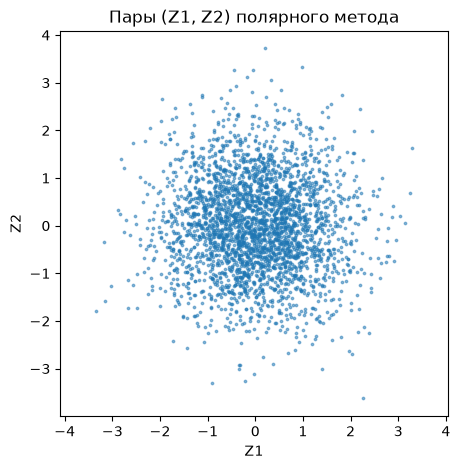

In [20]:
z1, z2 = z_polar[0::2], z_polar[1::2]     # чётные - Z1, нечётные - Z2 из той же пары

r_lin, p_lin = stats.pearsonr(z1, z2)
r_sq, p_sq = stats.pearsonr(z1 ** 2, z2 ** 2)
print(f"corr(Z1, Z2)     = {r_lin:+.5f}, p = {p_lin:.3f}")
print(f"corr(Z1², Z2²)   = {r_sq:+.5f}, p = {p_sq:.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(z1[:3000], z2[:3000], s=3, alpha=0.5)
plt.title("Пары (Z1, Z2) полярного метода")
plt.xlabel("Z1"); plt.ylabel("Z2"); plt.axis("equal")
plt.show()

Облако точек круглое, без вытянутости, а обе корреляции близки к нулю. Для нормальных величин некоррелированность означает независимость, по этому утверждение статьи подтверждается.


**Тест 5 - Ключевой. Сравнение датчика с реальными X1.** Генерируем столько же значений, сколько реальных измерений (1960), с параметрами $\hat\mu, \hat\sigma$ из данных.

               X1 (реальные)  Полярный метод  разница, %
n                   1960.000        1960.000       0.000
mean                3550.865        3561.212       0.291
std                  428.902         427.372      -0.357
skew                   0.047          -0.018    -138.159
kurt (excess)         -0.356          -0.037      89.632
q05                 2838.950        2847.746       0.310
q25                 3247.000        3278.453       0.969
median              3556.000        3558.762       0.078
q75                 3862.000        3858.299      -0.096
q95                 4237.000        4252.838       0.374

Двухвыборочный Колмогоров–Смирнов: D = 0.0281, p = 0.423


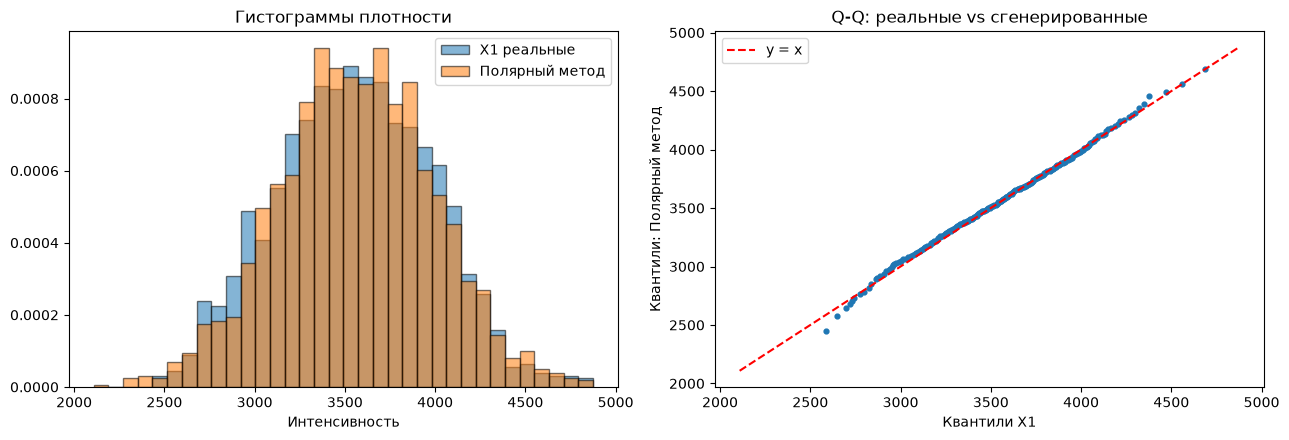

In [21]:
gen_polar = polar_normal(N_REAL, mu=mu_hat, sigma=sigma_hat, seed=42)
p_ks2_polar = compare_with_real(X1, gen_polar, "Полярный метод")
plot_vs_real(X1, gen_polar, "Полярный метод")

Идеально совпало! Графики демонстрируют, что наши сгенерироанные величины получились практически такие же как Х1.

### RESUME

* Пошаговая реализация по статье и быстрая векторная версия дают одинаковые числа; векторная работает в десятки раз быстрее.
* Доля принятых точек и расход равномерных чисел совпали с теоретическими $\pi/4$ и $4/\pi$ - алгоритм ведёт себя ровно так, как описано в статье.
* На миллионе чисел среднее, дисперсия, асимметрия, эксцесс и квантили совпадают с N(0,1), критерии Колмогорова и Шапиро-Уилка не отвергают нормальность.
* $Z_1$ и $Z_2$ одной пары некоррелированы (в том числе их квадраты), то есть независимы.
* Среднее, стандартное отклонение и медиана сгенерированных значений совпадают с X1; двухвыборочный критерий Колмогорова–Смирнова сравнивает их с реальными данными. Самые заметные расхождения ожидаются в эксцессе и в хвостах (квантили 5% и 95%), но это не ошибка датчика, а ограничение модели X1 нормальна.